<a href="https://colab.research.google.com/github/hyunwook3910/hackathon/blob/main/trash_classfication.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mostafaabla/garbage-classification")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'garbage-classification' dataset.
Path to dataset files: /kaggle/input/garbage-classification


In [2]:
# 1. 데이터 학습 전 데이터 확인
import os, random
from collections import Counter
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# 1) 폴더 구조 보기 (깊이 3까지)
for root, dirs, files in os.walk(path):
    depth = root[len(path):].count(os.sep)
    if depth <= 3:
        print("  " * depth + os.path.basename(root), f"(폴더 {len(dirs)}, 파일 {len(files)})")

garbage-classification (폴더 1, 파일 0)
  garbage_classification (폴더 12, 파일 0)
    metal (폴더 0, 파일 769)
    white-glass (폴더 0, 파일 775)
    biological (폴더 0, 파일 985)
    paper (폴더 0, 파일 1050)
    brown-glass (폴더 0, 파일 607)
    battery (폴더 0, 파일 945)
    trash (폴더 0, 파일 697)
    cardboard (폴더 0, 파일 891)
    shoes (폴더 0, 파일 1977)
    clothes (폴더 0, 파일 5325)
    plastic (폴더 0, 파일 865)
    green-glass (폴더 0, 파일 629)


In [3]:
# 2) 클래스 폴더가 있는 위치 자동 탐색: 이미지 파일을 직접 가진 폴더들의 부모
IMG_EXT = (".jpg", ".jpeg", ".png")
class_dirs = {}
for root, dirs, files in os.walk(path):
    imgs = [f for f in files if f.lower().endswith(IMG_EXT)]
    if imgs:
        class_dirs[root] = imgs

data_dir = os.path.dirname(next(iter(class_dirs)))
print("data_dir:", data_dir)

# 3) 클래스별 개수 (불균형 확인)
rows = [(os.path.basename(d), len(f)) for d, f in class_dirs.items()]
df = pd.DataFrame(rows, columns=["class", "count"]).sort_values("count", ascending=False)
df["ratio(%)"] = (df["count"] / df["count"].sum() * 100).round(1)
print(df.to_string(index=False))
print("전체:", df["count"].sum(), "| 클래스 수:", len(df))

data_dir: /kaggle/input/garbage-classification/garbage_classification
      class  count  ratio(%)
    clothes   5325      34.3
      shoes   1977      12.7
      paper   1050       6.8
 biological    985       6.3
    battery    945       6.1
  cardboard    891       5.7
    plastic    865       5.6
white-glass    775       5.0
      metal    769       5.0
      trash    697       4.5
green-glass    629       4.1
brown-glass    607       3.9
전체: 15515 | 클래스 수: 12


In [4]:
# 4) 이미지 크기·모드 확인 (클래스마다 30장씩 표본)
random.seed(42)
sizes, modes = [], Counter()
for d, files in class_dirs.items():
    for f in random.sample(files, min(30, len(files))):
        with Image.open(os.path.join(d, f)) as im:
            sizes.append(im.size)
            modes[im.mode] += 1

sz = pd.DataFrame(sizes, columns=["width", "height"])
print(sz.describe().round(1))
print("모드:", dict(modes))   # RGB가 아닌 것(RGBA, L 등)이 섞여 있는지 확인

       width  height
count  360.0   360.0
mean   317.0   283.1
std    124.3   111.3
min    132.0   115.0
25%    225.0   200.0
50%    259.0   225.0
75%    400.0   384.0
max    865.0   711.0
모드: {'RGB': 359, 'P': 1}


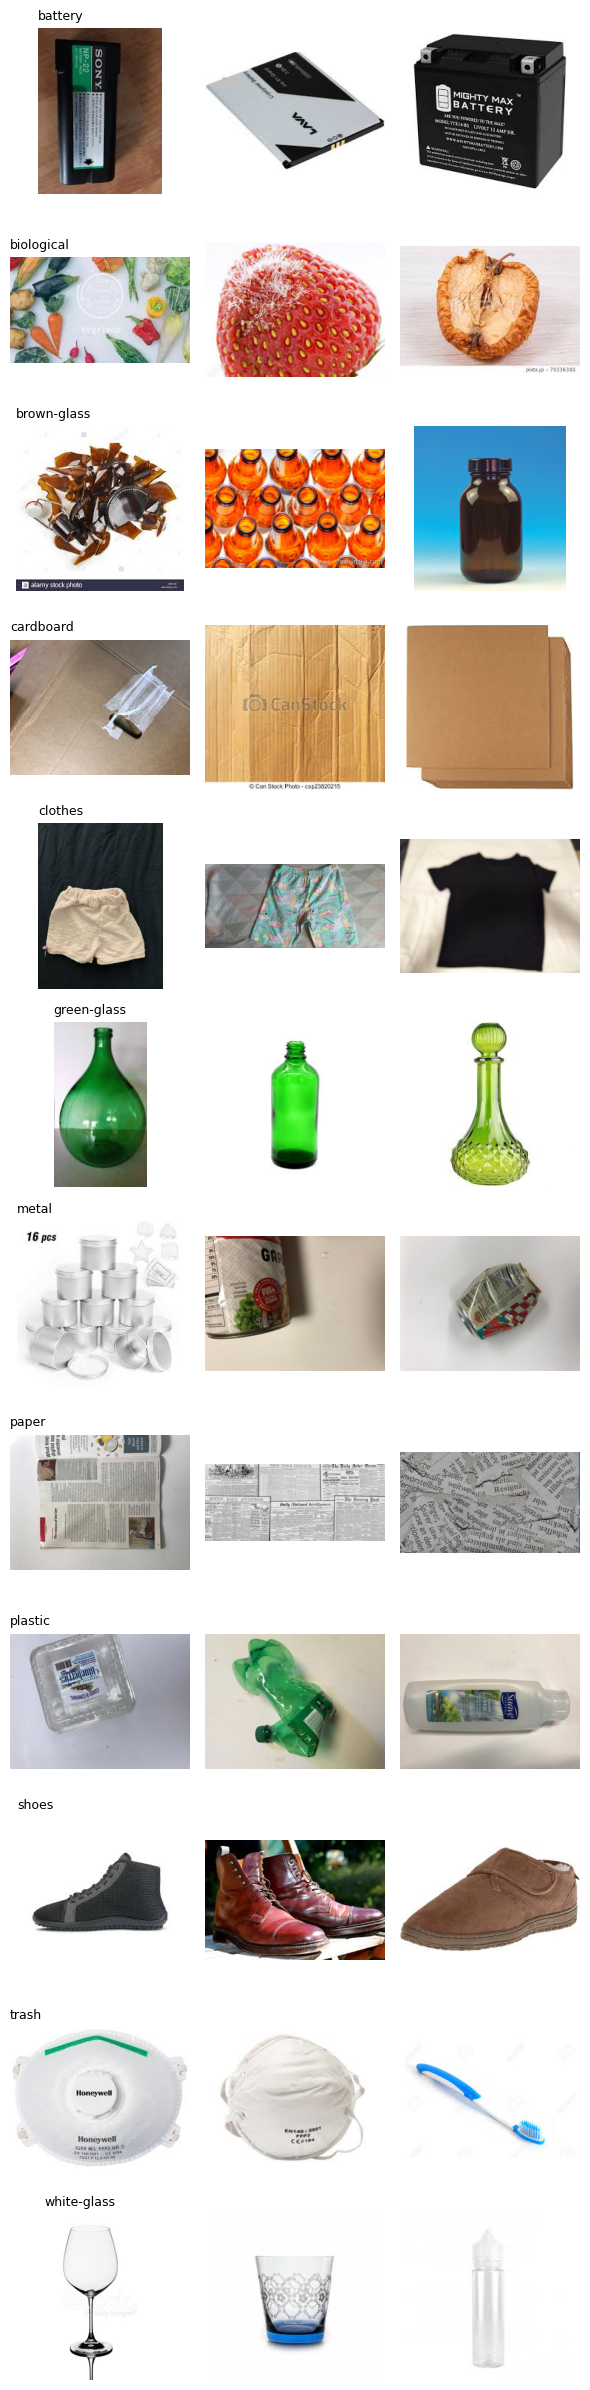

In [5]:
# 5) 클래스별 샘플 이미지 (클래스당 3장)
names = sorted(class_dirs, key=lambda d: os.path.basename(d))
fig, axes = plt.subplots(len(names), 3, figsize=(6, 2 * len(names)))
for i, d in enumerate(names):
    for j, f in enumerate(random.sample(class_dirs[d], 3)):
        axes[i, j].imshow(Image.open(os.path.join(d, f)).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(os.path.basename(d), fontsize=9, loc="left")
plt.tight_layout()
plt.show()